In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
import os
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Define the device (GPU if available)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Define paths
train_path = r"D:\deeplearning\vscode deep\Birds_25\train"
val_path = r"D:\deeplearning\vscode deep\Birds_25\val"
test_path = r"D:\deeplearning\vscode deep\Birds_25\test"

# Define data transformations
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}


In [3]:
# Load datasets using ImageFolder
train_dataset = datasets.ImageFolder(root=train_path, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(root=val_path, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(root=test_path, transform=data_transforms['test'])

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# Load MobileNetV3-Large model pretrained on ImageNet
model = models.mobilenet_v3_large(pretrained=True)

# Modify the final layer to match the number of classes in your dataset
num_ftrs = model.classifier[3].in_features
model.classifier[3] = nn.Linear(num_ftrs, len(train_dataset.classes))

# Move the model to the device (GPU or CPU)
model = model.to(device)


c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\bhore\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Large_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Large_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [12]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer: RMSprop
optimizer = optim.RMSprop(model.parameters(), lr=0.001, alpha=0.99, weight_decay=1e-4)



In [13]:
# Set the number of epochs
num_epochs = 20

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 10)

    # Training phase
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        # Backward pass + optimization
        loss.backward()
        optimizer.step()

        # Track loss and accuracy
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_dataset)
    epoch_acc = running_corrects.double() / len(train_dataset)

    print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

    val_loss = val_loss / len(val_dataset)
    val_acc = val_corrects.double() / len(val_dataset)

    print(f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}')

print('Training complete')


Epoch 1/20
----------
Train Loss: 0.1867 Acc: 0.9447
Val Loss: 0.3718 Acc: 0.9194
Epoch 2/20
----------
Train Loss: 0.1403 Acc: 0.9558
Val Loss: 0.1472 Acc: 0.9522
Epoch 3/20
----------
Train Loss: 0.1334 Acc: 0.9582
Val Loss: 0.1157 Acc: 0.9636
Epoch 4/20
----------
Train Loss: 0.1269 Acc: 0.9607
Val Loss: 0.4143 Acc: 0.8854
Epoch 5/20
----------
Train Loss: 0.1234 Acc: 0.9613
Val Loss: 0.2782 Acc: 0.9219
Epoch 6/20
----------
Train Loss: 0.1152 Acc: 0.9640
Val Loss: 0.1205 Acc: 0.9585
Epoch 7/20
----------
Train Loss: 0.1076 Acc: 0.9655
Val Loss: 0.1321 Acc: 0.9574
Epoch 8/20
----------
Train Loss: 0.1062 Acc: 0.9666
Val Loss: 0.0833 Acc: 0.9716
Epoch 9/20
----------
Train Loss: 0.0991 Acc: 0.9687
Val Loss: 0.2181 Acc: 0.9371
Epoch 10/20
----------
Train Loss: 0.0991 Acc: 0.9689
Val Loss: 0.1595 Acc: 0.9508
Epoch 11/20
----------
Train Loss: 0.1014 Acc: 0.9684
Val Loss: 0.2593 Acc: 0.9314
Epoch 12/20
----------
Train Loss: 0.0958 Acc: 0.9692
Val Loss: 0.1709 Acc: 0.9444
Epoch 13/20
-

In [1]:
# Save the trained model's state dictionary
model_save_path = 'mobilenetv3_large_bird_classification.pth'
torch.save(model.state_dict(), model_save_path)

print(f"Model saved to {model_save_path}")


NameError: name 'torch' is not defined

Test Loss: 0.1443 Acc: 0.9568


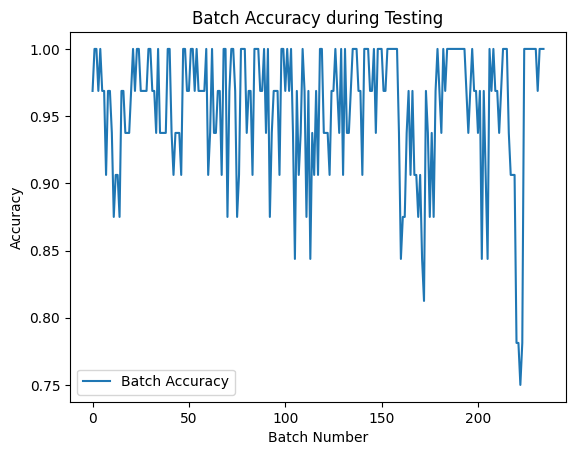

In [15]:
# Testing phase
model.eval()
test_loss = 0.0
test_corrects = 0
accuracy_list = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * inputs.size(0)
        test_corrects += torch.sum(preds == labels.data)
        
        # Calculate accuracy for each batch
        batch_acc = torch.sum(preds == labels.data).double() / inputs.size(0)
        accuracy_list.append(batch_acc.item())

test_loss = test_loss / len(test_dataset)
test_acc = test_corrects.double() / len(test_dataset)

print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

# Plot accuracy for each batch
plt.plot(accuracy_list, label='Batch Accuracy')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy')
plt.title('Batch Accuracy during Testing')
plt.legend()
plt.show()


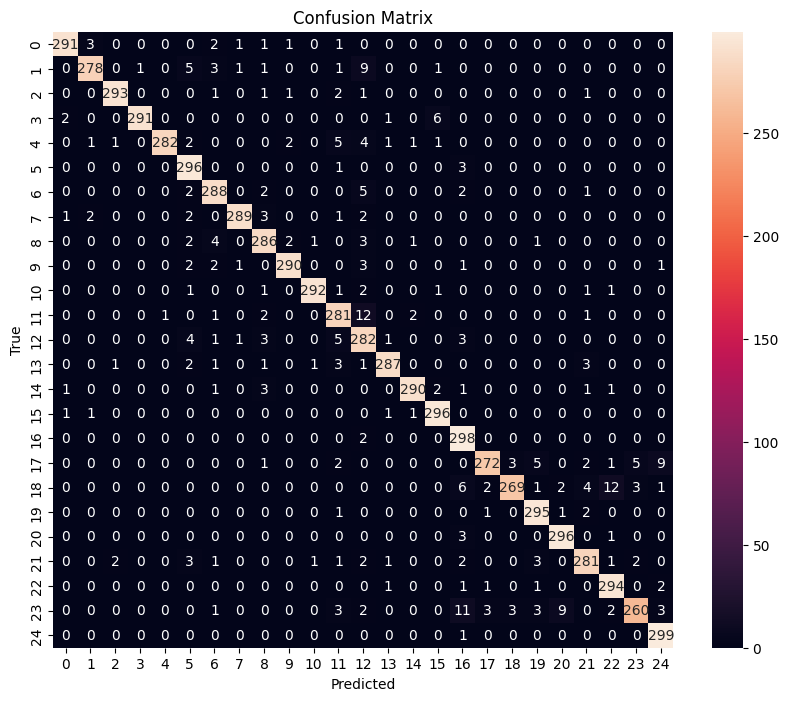

In [16]:
# Compute and plot confusion matrix
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [17]:
from sklearn.metrics import classification_report

# Collect all predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate classification report
report = classification_report(all_labels, all_preds, target_names=test_dataset.classes)
print(report)


                           precision    recall  f1-score   support

    Asian-Green-Bee-Eater       0.98      0.97      0.98       300
      Brown-Headed-Barbet       0.98      0.93      0.95       300
             Cattle-Egret       0.99      0.98      0.98       300
        Common-Kingfisher       1.00      0.97      0.98       300
              Common-Myna       1.00      0.94      0.97       300
         Common-Rosefinch       0.92      0.99      0.95       300
        Common-Tailorbird       0.94      0.96      0.95       300
       Coppersmith-Barbet       0.99      0.96      0.97       300
           Forest-Wagtail       0.94      0.95      0.95       300
             Gray-Wagtail       0.98      0.97      0.97       300
                   Hoopoe       0.99      0.97      0.98       300
               House-Crow       0.91      0.94      0.92       300
     Indian-Grey-Hornbill       0.85      0.94      0.90       300
           Indian-Peacock       0.98      0.96      0.97     